<a href="https://colab.research.google.com/github/NitinKarthik01/AIML_MSIS/blob/main/Lab_Test(13_10_26).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [39]:
import numpy as np
import pandas as pd
import matplotlib as plt

from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, recall_score, f1_score, precision_score, confusion_matrix)

In [58]:
# a) preprocess the dataset and train a logistic regression
# classifier using a suitable train_testsplit, explain the role of sigmod function


url = "/content/bank-full.csv"

df = pd.read_csv(url,sep=";")

print(df.head())
print()
print("Shape of the Dataset : ", df.shape)
print()



#checking for Null Values
missing = df.isnull().sum()
print(missing)
print()
if(missing.sum() == 0):
  display("No NULL VALUES")



# Seperating data and target
X = df.drop(columns=["y", "duration"])
Y = df["y"].map({"yes": 1, "no": 0})



#checking for categorical data and applying Encoding Techniques
cat_cols = X.select_dtypes(include=["object"]).columns

encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)

X_encoded = encoder.fit_transform(X[cat_cols])
X_encoded = pd.DataFrame(
    X_encoded,
    columns=encoder.get_feature_names_out(cat_cols),
    index=X.index)

X = pd.concat(
    [X.drop(columns=cat_cols), X_encoded],
    axis=1)

print(X.head())
print()
print(X.shape)
print()



#train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42)
print("No. of records in Train Split : ",len(X_train))
print()
print("No. of records in Test Split : ",len(X_test))



#Scalin the Features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
print("Model trained successfully")

   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married    unknown      no     1506     yes   no   
4   33       unknown   single    unknown      no        1      no   no   

   contact  day month  duration  campaign  pdays  previous poutcome   y  
0  unknown    5   may       261         1     -1         0  unknown  no  
1  unknown    5   may       151         1     -1         0  unknown  no  
2  unknown    5   may        76         1     -1         0  unknown  no  
3  unknown    5   may        92         1     -1         0  unknown  no  
4  unknown    5   may       198         1     -1         0  unknown  no  

Shape of the Dataset :  (45211, 17)

age          0
job          0
marital      0
education    0
default      

'No NULL VALUES'

   age  balance  day  campaign  pdays  previous  job_admin.  job_blue-collar  \
0   58     2143    5         1     -1         0         0.0              0.0   
1   44       29    5         1     -1         0         0.0              0.0   
2   33        2    5         1     -1         0         0.0              0.0   
3   47     1506    5         1     -1         0         0.0              1.0   
4   33        1    5         1     -1         0         0.0              0.0   

   job_entrepreneur  job_housemaid  ...  month_jun  month_mar  month_may  \
0               0.0            0.0  ...        0.0        0.0        1.0   
1               0.0            0.0  ...        0.0        0.0        1.0   
2               1.0            0.0  ...        0.0        0.0        1.0   
3               0.0            0.0  ...        0.0        0.0        1.0   
4               0.0            0.0  ...        0.0        0.0        1.0   

   month_nov  month_oct  month_sep  poutcome_failure  poutcome

In [56]:
# b) report accuracy, f1_score, precision, recall.
#  compare predictions using threshold of 0.3 and 0.5


for t in [0.3, 0.5]:
    y_pred = (y_prob >= t).astype(int)
    print("Threshold:", t)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, zero_division=0))
    print("Recall:", recall_score(y_test, y_pred, zero_division=0))
    print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
    print()


results = []

for t in [0.3, 0.5]:
    y_pred = (y_prob >= t).astype(int)

    results.append({
        "Threshold": t,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0)
    })

comparison = pd.DataFrame(results)
display(comparison.round(4))

Threshold: 0.3
Accuracy: 0.885989162888422
Precision: 0.5471698113207547
Recall: 0.31897341888175984
F1 Score: 0.4030110017371164

Threshold: 0.5
Accuracy: 0.8901913081941834
Precision: 0.6689655172413793
Recall: 0.1778185151237397
F1 Score: 0.2809558291093411



,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.3,0.8860,0.5472,0.3190,0.403
1,0.5,0.8902,0.6690,0.1778,0.281


In [62]:
# train logistic regression models using
# L1 and L2 regularization and comapre their f1 scores adnd coefficients values


# train logistic regression
model_l1 = LogisticRegression(penalty="l1", solver="liblinear", max_iter=1000)
model_l2 = LogisticRegression(penalty="l2", solver="liblinear", max_iter=1000)

model_l1.fit(X_train, y_train)
model_l2.fit(X_train, y_train)

y_pred_l1 = model_l1.predict(X_test)
y_pred_l2 = model_l2.predict(X_test)



comparison = pd.DataFrame({
    "Model": ["L1 Regularization", "L2 Regularization"],
    "F1 Score": [
        f1_score(y_test, y_pred_l1),
        f1_score(y_test, y_pred_l2)
    ]
})

display(comparison)




coefficients = pd.DataFrame({
    "Feature": X.columns,
    "L1 Coefficient": model_l1.coef_[0],
    "L2 Coefficient": model_l2.coef_[0]
})

display(coefficients.round(4))


print("L1 Zero Coefficients:", (model_l1.coef_[0] == 0).sum())
print("L2 Zero Coefficients:", (model_l2.coef_[0] == 0).sum())

,Model,F1 Score
0,L1 Regularization,0.280956
1,L2 Regularization,0.280956


,Feature,L1 Coefficient,L2 Coefficient
0,age,0.0254,0.0261
1,balance,0.0455,0.0456
2,day,0.0349,0.0358
3,campaign,-0.2652,-0.2657
4,pdays,-0.0041,-0.0051
5,previous,0.0204,0.0206
6,job_admin.,0.0192,0.0121
7,job_blue-collar,-0.0229,-0.0324
8,job_entrepreneur,-0.0085,-0.0130
9,job_housemaid,-0.0293,-0.0334


L1 Zero Coefficients: 6
L2 Zero Coefficients: 0


,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.3,0.8860,0.5472,0.3190,0.403
1,0.5,0.8902,0.6690,0.1778,0.281


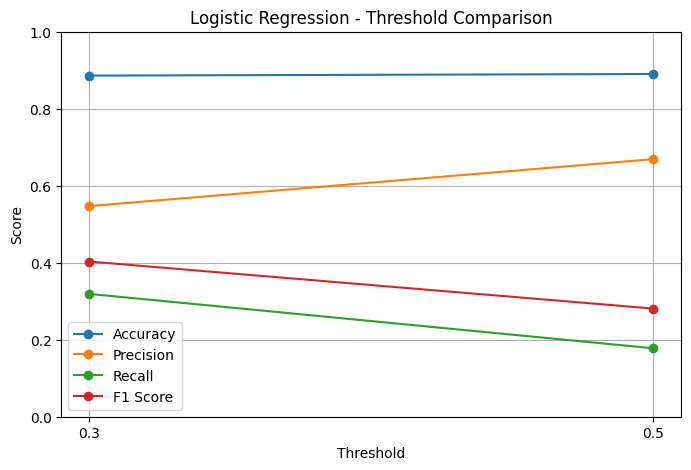

In [66]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

for t in [0.3, 0.5]:
    y_pred = (y_prob >= t).astype(int)

    results.append({
        "Threshold": t,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0)
    })

threshold_comparison = pd.DataFrame(results)

display(threshold_comparison.round(4))

threshold_comparison.set_index("Threshold").plot(
    kind="line",
    marker="o",
    figsize=(8, 5)
)

plt.title("Logistic Regression - Threshold Comparison")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.xticks([0.3, 0.5])
plt.ylim(0, 1)
plt.grid(True)
plt.show()

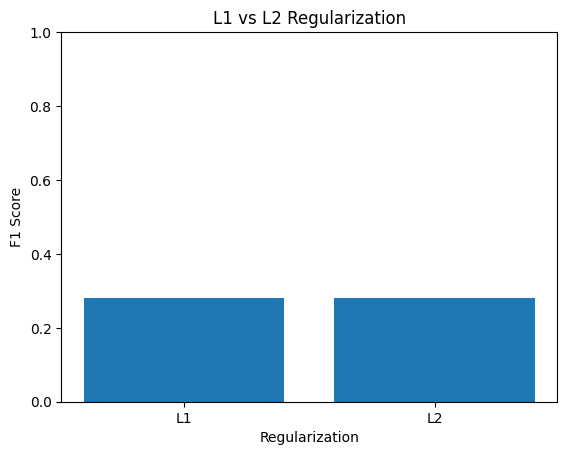

In [64]:
f1_l1 = f1_score(y_test, y_pred_l1)
f1_l2 = f1_score(y_test, y_pred_l2)

plt.bar(["L1", "L2"], [f1_l1, f1_l2])

plt.title("L1 vs L2 Regularization")
plt.xlabel("Regularization")
plt.ylabel("F1 Score")
plt.ylim(0, 1)
plt.show()

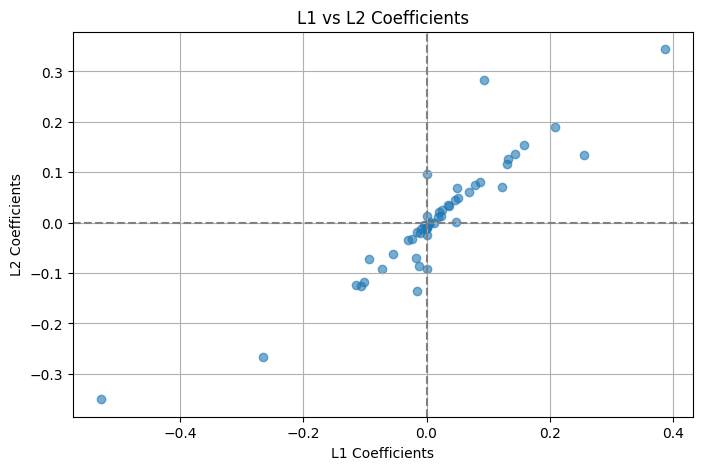

In [65]:
plt.figure(figsize=(8, 5))

plt.scatter(
    model_l1.coef_[0],
    model_l2.coef_[0],
    alpha=0.6
)

plt.axhline(0, linestyle="--", color="gray")
plt.axvline(0, linestyle="--", color="gray")

plt.title("L1 vs L2 Coefficients")
plt.xlabel("L1 Coefficients")
plt.ylabel("L2 Coefficients")
plt.grid(True)
plt.show()